[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/isocan/ML-accelerated-ORR/blob/main/notebooks/06_stageIII_vasp_orr_thermodynamics.ipynb)

# Stage III | Oxygen reduction thermodynamics from VASP outputs

This worked example shows how to convert archived VASP electronic energies and VaspGibbs corrections into adsorption free energies, limiting potentials, and thermodynamic overpotentials for the oxygen reduction reaction (ORR). It follows the computational hydrogen electrode (CHE) convention for O*, OH*, and OOH* and compares two alloy surfaces with Pt(111).

| Surface | Archive identifier |
| :--- | :--- |
| Ni₃Sb(111) | `mp-10260_111` |
| CuPt₇(111) | `mp-12608_111` |
| Pt(111) | `mp-126_111` |

Select **Runtime → Run all** in a CPU Colab session. The calculation uses public input archives pinned to a Git commit and runs in Python. The reference table, adsorption energies, and figures appear below their corresponding cells. Section 6 provides the CSV tables and figure files.

### Computational scope

The public example uses the non-spin-polarized RPBE-D3 zero-damping settings of the OC25/eSEN workflow (`IVDW=11`, 400 eV cutoff, Gaussian smearing of 0.10 eV, and a dipole correction normal to the slabs). The notebook starts from completed calculations and uses the final $E_{\sigma\to0}$ values. For this public dataset, VASPsol electronic energies come from the final ionic steps of the archived relaxations with $\varepsilon=80$. The manuscript protocol evaluates the corresponding VASPsol energy difference at fixed geometry. The same CHE equations apply to both protocols.

[Public data archives](https://github.com/isocan/ML-accelerated-ORR/tree/61d191199ad4878c5afed0dcbd9094ee769d2132/data/demo_data) · [Computational hydrogen electrode](https://doi.org/10.1021/jp047349j) · [VaspGibbs](https://github.com/ftherrien/VaspGibbs) · [VASPsol](https://doi.org/10.1063/1.4865107)

## 1. Load the calculation archives

Each slab archive contains a clean slab and the three covered states. Each state has a vacuum `OUTCAR`, a `Sol/OUTCAR`, and a vacuum `Freq_vac/VaspGibbs.md` report. The H₂ and H₂O archive provides the molecular electronic energies and thermochemical corrections. The cell verifies the archive checksums before reading the calculation outputs.

In [1]:
%pip -q install "numpy==2.3.5" "pandas==2.2.3" "matplotlib==3.10.8"

In [2]:
from hashlib import sha256
from io import BytesIO
import json
import re
import shutil
import sys
import tempfile
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZIP_DEFLATED, ZipFile

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

DATA_COMMIT = "61d191199ad4878c5afed0dcbd9094ee769d2132"
DATA_URL = f"https://raw.githubusercontent.com/isocan/ML-accelerated-ORR/{DATA_COMMIT}/data/demo_data"
SURFACES = {
    "mp-10260_111": "Ni₃Sb(111)",
    "mp-12608_111": "CuPt₇(111)",
    "mp-126_111": "Pt(111)",
}
PT_REFERENCE = "mp-126_111"
STATES = ("Slab", "O", "OH", "OOH")
WORK_ROOT = Path.cwd()
INPUT_DIR = WORK_ROOT / "stageIII_inputs"
RESULTS_DIR = WORK_ROOT / "stageIII_ORR_results"
INPUT_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
INPUT_HASHES = {
    "Molecules.zip": "19fc8b5e81bdc7176cdbfc32b9cf879a09a1c2c8482fb1ce11eaf06b23ff49dd",
    "mp-10260_111.zip": "8c9d484bff24c2382e04555ff170ac70582e7470a83404784c4396653e21de87",
    "mp-12608_111.zip": "45eed535886a0e8f479c24122e51c7f9f5cf3474ee1d4e1b2d2cf1adba89e3a0",
    "mp-126_111.zip": "b994092d789dead581ef41b7a32fc5e08bb494471afbaddf00c56b39e8723e22",
}


def fetch_archive(name, expected_hash):
    """Cache an archive only after validating its SHA-256 checksum."""
    destination = INPUT_DIR / name
    if destination.is_file() and sha256(destination.read_bytes()).hexdigest() == expected_hash:
        return destination
    with tempfile.NamedTemporaryFile(dir=INPUT_DIR, delete=False) as handle:
        temporary = Path(handle.name)
    try:
        with urlopen(f"{DATA_URL}/{name}", timeout=120) as response, temporary.open("wb") as handle:
            shutil.copyfileobj(response, handle)
        if sha256(temporary.read_bytes()).hexdigest() != expected_hash:
            raise ValueError(f"Archive checksum mismatch for {name}")
        temporary.replace(destination)
    finally:
        temporary.unlink(missing_ok=True)
    return destination


archives = {name: fetch_archive(name, digest) for name, digest in INPUT_HASHES.items()}
print(f"Verified {len(archives)} input archives.")

Verified 4 input archives.


## 2. Obtain state energies and molecular references

The thermochemical correction for each state is obtained from its archived VaspGibbs report at $T=298.15$ K.

$$
q_j = E_{\mathrm{ZPE},j} + H_{\mathrm{thermal},j} - TS_j,
\qquad
G_j = E_{\sigma\to 0,j} + q_j .
$$

$H_{\mathrm{thermal}}$ is the finite-temperature enthalpy above the electronic energy and ZPE. It includes the rotational, translational, and ideal-gas $pV$ terms for molecules. Surface states use the corresponding vacuum thermochemical corrections in both environments.

The CHE uses H₂(g) at 100 kPa and H₂O(l) at unit activity. The liquid-water chemical potential is represented by H₂O(g) at its saturation pressure (3.16675 kPa). The molecular reports were evaluated at 100 kPa. The ideal-gas conversion $k_{\mathrm B}T\ln(p_{\mathrm{target}}/p_{\mathrm{source}})$ is applied once to each molecular free energy. In the component table, this pressure dependence is included in $TS$. [Water vapor-pressure data](https://webbook.nist.gov/cgi/cbook.cgi?ID=C7732185&Mask=4)

In [3]:
TEMPERATURE_K = 298.15
KB_EV_K = 8.6173332621452e-5
# Antoine equation for water (NIST, 273–303 K), converted from bar to kPa.
WATER_PRESSURE_KPA = 100.0 * 10**(5.40221 - 1838.675 / (TEMPERATURE_K - 31.737))
TARGET_PRESSURE_KPA = {"H2": 100.0, "H2O": WATER_PRESSURE_KPA}
NUMBER = r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[EeDd][+-]?\d+)?"
SIGMA_ZERO = re.compile(rb"energy\(sigma->0\)\s*=\s*(" + NUMBER.encode() + rb")")
THERMAL_TERMS = ("ZPE_eV", "H_thermal_eV", "TS_eV")


def read_electronic_energy(archive, member):
    """Return the last zero-smearing electronic energy from a completed OUTCAR."""
    final_value = None
    completed = False
    with archive.open(member) as stream:
        for line in stream:
            match = SIGMA_ZERO.search(line)
            if match:
                final_value = float(match[1].replace(b"D", b"E").replace(b"d", b"e"))
            completed |= b"General timing and accounting informations for this job" in line
    if not completed or final_value is None or not np.isfinite(final_value):
        raise ValueError(f"Expected a completed VASP calculation with a finite energy in {member}")
    return final_value


def read_thermochemistry(archive, member, molecule=None):
    """Read the published VaspGibbs terms and convert molecular standard states."""
    report = archive.read(member).decode()
    rows = {}
    for line in report.splitlines():
        if line.lstrip().startswith("|"):
            label, *fields = (field.strip() for field in line.strip().strip("|").split("|"))
            rows[label] = fields

    def value(label, column=0):
        match = re.match(NUMBER, rows[label][column])
        if match is None:
            raise ValueError(f"Invalid VaspGibbs field {label} in {member}")
        return float(match[0].replace("D", "E").replace("d", "e"))

    temperature = value("Temperature")
    is_molecular = bool(re.search(r"This system is a (?:linear )?molecule", report))
    if not np.isclose(temperature, TEMPERATURE_K, rtol=0, atol=0.01) or is_molecular != bool(molecule):
        raise ValueError(f"Unexpected temperature or thermochemistry model in {member}")

    zpe = value("ZPE", 1)
    thermal_enthalpy = value("Electronic", 1) + value("Vibrational", 1)
    pressure_source = pressure_target = None
    pressure_shift = 0.0
    if molecule is not None:
        pressure_source = value("Pressure")
        pressure_target = TARGET_PRESSURE_KPA[molecule]
        if pressure_source <= 0 or value("Sigma") != 2 or value("Electronic") != 1:
            raise ValueError(f"Unexpected molecular pressure, symmetry number, or degeneracy in {member}")
        kbt = KB_EV_K * temperature
        thermal_enthalpy += value("Rotational", 1) + value("Translational", 1) + kbt
        pressure_shift = kbt * np.log(pressure_target / pressure_source)

    ts = value("TS") - pressure_shift
    correction = value("G - E_dft") + pressure_shift
    if not np.isclose(zpe + thermal_enthalpy - ts, correction, rtol=0, atol=5e-6):
        raise ValueError(f"Thermochemical components disagree with the VaspGibbs total in {member}")

    return {
        "ZPE_eV": zpe, "H_thermal_eV": thermal_enthalpy, "TS_eV": ts,
        "q_eV": correction, "report_E_DFT_eV": value("DFT Total Energy"),
        "source_pressure_kPa": pressure_source, "target_pressure_kPa": pressure_target,
        "pressure_shift_eV": pressure_shift, "VaspGibbs_source": member,
    }


def read_state(archive, state_path, molecule=None):
    """Combine vacuum electronic energy, thermochemistry, and VASPsol energy."""
    vacuum_path = f"{state_path}/OUTCAR"
    vacuum = read_electronic_energy(archive, vacuum_path)
    thermal = read_thermochemistry(archive, f"{state_path}/Freq_vac/VaspGibbs.md", molecule)
    if abs(vacuum - thermal["report_E_DFT_eV"]) > 5e-4:
        raise ValueError(f"Electronic energy does not match the report baseline for {state_path}")
    solvent_path = None if molecule else f"{state_path}/Sol/OUTCAR"
    solvent = None if molecule else read_electronic_energy(archive, solvent_path)
    return {
        "E_vac_eV": vacuum, "E_sol_eV": solvent, **thermal,
        "G_vac_eV": vacuum + thermal["q_eV"],
        "G_sol_eV": None if molecule else solvent + thermal["q_eV"],
        "vacuum_OUTCAR": vacuum_path, "solvent_OUTCAR": solvent_path,
    }


with ZipFile(archives["Molecules.zip"]) as archive:
    molecular = pd.DataFrame.from_dict({
        molecule: read_state(archive, f"Molecules/{molecule}", molecule)
        for molecule in TARGET_PRESSURE_KPA
    }, orient="index").rename_axis("Molecule")

surface_rows = []
for surface_id, label in SURFACES.items():
    with ZipFile(archives[f"{surface_id}.zip"]) as archive:
        for state in STATES:
            surface_rows.append({
                "Surface ID": surface_id, "Surface": label, "State": state,
                **read_state(archive, f"{surface_id}/{state}"),
            })

surface_states = pd.DataFrame(surface_rows).set_index(["Surface ID", "State"], verify_integrity=True)
reference_columns = {
    "target_pressure_kPa": "Pressure (kPa)",
    "E_vac_eV": "Electronic E (eV)",
    "ZPE_eV": "ZPE (eV)",
    "H_thermal_eV": "Thermal H (eV)",
    "TS_eV": "TS (eV)",
    "q_eV": "q (eV)",
    "G_vac_eV": "G (eV)",
}
display(molecular[list(reference_columns)].rename(columns=reference_columns).round(5))

,Pressure (kPa),Electronic E (eV),ZPE (eV),Thermal H (eV),TS (eV),q (eV),G (eV)
Molecule,,,,,,,
H2,100.00000,-6.97862,0.26871,0.08992,0.40265,-0.04402,-7.02264
H2O,3.16675,-14.17520,0.56483,0.10286,0.67265,-0.00496,-14.18016


## 3. Calculate adsorption free energies

For adsorbate $X^*$, use the clean slab $*$ and the appropriate molecular combination $R_X$.

$$
\begin{aligned}
R_{\mathrm{O}^*} &= \mu_{\mathrm{H_2O}} - \mu_{\mathrm{H_2}},\\
R_{\mathrm{OH}^*} &= \mu_{\mathrm{H_2O}} - \tfrac12\mu_{\mathrm{H_2}},\\
R_{\mathrm{OOH}^*} &= 2\mu_{\mathrm{H_2O}} - \tfrac32\mu_{\mathrm{H_2}}.
\end{aligned}
$$

The same stoichiometric coefficients are applied to the electronic and thermochemical terms. For example, $\Delta G_{\mathrm{vac}}(\mathrm{O}^*) = G_{\mathrm{slab+O}}-G_{\mathrm{slab}}-\mu_{\mathrm{H_2O}}+\mu_{\mathrm{H_2}}$. The solvent contribution is a covered-minus-clean electronic difference.

$$
\begin{aligned}
\delta E_{\mathrm{solv}}(X^*) &=
 (E_{\mathrm{slab}+X}^{\mathrm{sol}}-E_{\mathrm{slab}}^{\mathrm{sol}})
 -(E_{\mathrm{slab}+X}^{\mathrm{vac}}-E_{\mathrm{slab}}^{\mathrm{vac}}),\\
\Delta G_{\mathrm{sol}}(X^*) &=
 \Delta E_{\mathrm{vac}}(X^*) + \Delta G_{\mathrm{therm}}(X^*)
 + \delta E_{\mathrm{solv}}(X^*).
\end{aligned}
$$

The table shows the contribution of each term in eV. The exported adsorption table also gives the separate $\Delta\mathrm{ZPE}$, $\Delta H_{\mathrm{thermal}}$, and $T\Delta S$ components.

In [4]:
# Coefficients of H2O and H2 in the molecular reference R_X.
CHE_COEFFICIENTS = {"O": (1.0, -1.0), "OH": (1.0, -0.5), "OOH": (2.0, -1.5)}
reference_terms = ["E_vac_eV", *THERMAL_TERMS, "q_eV", "G_vac_eV"]
adsorption_rows = []

for surface_id, label in SURFACES.items():
    states = surface_states.loc[surface_id]
    clean = states.loc["Slab"]
    for species, (n_water, n_hydrogen) in CHE_COEFFICIENTS.items():
        covered = states.loc[species]
        reference = (
            n_water * molecular.loc["H2O", reference_terms]
            + n_hydrogen * molecular.loc["H2", reference_terms]
        )
        delta_e_vac = covered["E_vac_eV"] - clean["E_vac_eV"] - reference["E_vac_eV"]
        delta_e_solv = (covered["E_sol_eV"] - clean["E_sol_eV"]) - (covered["E_vac_eV"] - clean["E_vac_eV"])
        thermal = {key: covered[key] - clean[key] - reference[key] for key in THERMAL_TERMS}
        delta_g_therm = covered["q_eV"] - clean["q_eV"] - reference["q_eV"]
        delta_g_vac = delta_e_vac + delta_g_therm
        delta_g_sol = delta_g_vac + delta_e_solv

        np.testing.assert_allclose(
            [delta_g_vac, delta_g_sol],
            [covered[f"G_{env}_eV"] - clean[f"G_{env}_eV"] - reference["G_vac_eV"]
             for env in ("vac", "sol")],
            rtol=0, atol=1e-8,
        )
        np.testing.assert_allclose(
            delta_g_therm, thermal["ZPE_eV"] + thermal["H_thermal_eV"] - thermal["TS_eV"],
            rtol=0, atol=2.5e-5,
        )

        adsorption_rows.append({
            "Surface ID": surface_id, "Surface": label, "Species": species,
            "DeltaE_vac_eV": delta_e_vac, **{f"Delta{key}": val for key, val in thermal.items()},
            "DeltaG_therm_eV": delta_g_therm, "DeltaE_solv_eV": delta_e_solv,
            "DeltaG_vac_eV": delta_g_vac, "DeltaG_sol_eV": delta_g_sol,
        })

adsorption = pd.DataFrame(adsorption_rows).set_index(["Surface ID", "Species"], verify_integrity=True)
adsorption_columns = {
    "Surface": "Surface", "DeltaE_vac_eV": "ΔE vacuum", "DeltaG_therm_eV": "ΔG thermal",
    "DeltaE_solv_eV": "δE solvent", "DeltaG_vac_eV": "ΔG vacuum", "DeltaG_sol_eV": "ΔG solvated",
}
adsorption_view = adsorption.reset_index()[["Species", *adsorption_columns]].rename(columns=adsorption_columns)
adsorption_view["Species"] += "*"
display(adsorption_view.set_index(["Surface", "Species"]).round(3))

ΔE vacuum  ΔG thermal  δE solvent  ΔG vacuum  ΔG solvated
Surface    Species                                                           
Ni₃Sb(111) O*           1.694      -0.034      -0.075      1.660        1.585
           OH*          0.730       0.189      -0.166      0.919        0.753
           OOH*         3.933       0.180      -0.213      4.113        3.899
CuPt₇(111) O*           1.274       0.036      -0.013      1.311        1.298
           OH*          0.667       0.199      -0.138      0.866        0.728
           OOH*         3.573       0.281      -0.214      3.854        3.639
Pt(111)    O*           1.224      -0.000      -0.014      1.224        1.209
           OH*          0.694       0.257      -0.139      0.951        0.812
           OOH*         3.554       0.273      -0.184      3.827        3.643

## 4. Determine the limiting potential and overpotential

For the associative ORR pathway, the forward reaction free energies at $U=0$ V vs RHE are

$$
\begin{aligned}
\Delta G_1 &= \Delta G_{\mathrm{OOH}^*} - 4.92\ \mathrm{eV},&
\Delta G_2 &= \Delta G_{\mathrm{O}^*} - \Delta G_{\mathrm{OOH}^*},\\
\Delta G_3 &= \Delta G_{\mathrm{OH}^*} - \Delta G_{\mathrm{O}^*},&
\Delta G_4 &= -\Delta G_{\mathrm{OH}^*}.
\end{aligned}
$$

Each step consumes one proton–electron pair, so $\Delta G_i(U)=\Delta G_i(0)+eU$. The limiting potential is $U_L=\min_i[-\Delta G_i(0)/e]$, the highest potential at which all steps are thermodynamically downhill or thermoneutral. The corresponding step is the potential-determining step (PDS), and the overpotential is $\eta=1.23\ \mathrm{V}-U_L$. Each alloy is compared with Pt(111) in the same environment.

In [5]:
U_EQ_V = 1.23
STEPS = ("O₂ → OOH*", "OOH* → O*", "O* → OH*", "OH* → H₂O")
ENVIRONMENTS = {"vac": "Vacuum", "sol": "Implicit solvent"}

orr_rows = []
for surface_id, label in SURFACES.items():
    for environment, environment_label in ENVIRONMENTS.items():
        g_o, g_oh, g_ooh = adsorption.loc[surface_id, f"DeltaG_{environment}_eV"].loc[list(CHE_COEFFICIENTS)]
        delta_g = np.array([g_ooh - 4 * U_EQ_V, g_o - g_ooh, g_oh - g_o, -g_oh])
        np.testing.assert_allclose(delta_g.sum(), -4 * U_EQ_V, rtol=0, atol=1e-10)
        pds = int(delta_g.argmax())
        u_limit = -delta_g[pds]  # eV per electron has the same numerical value as V.
        orr_rows.append({
            "Surface ID": surface_id, "Surface": label, "Environment": environment_label,
            **{f"DeltaG{i}_at_0V_eV": val for i, val in enumerate(delta_g, start=1)},
            "U_L_V_vs_RHE": u_limit, "eta_V": U_EQ_V - u_limit, "PDS": STEPS[pds],
        })

orr = pd.DataFrame(orr_rows).set_index(["Surface ID", "Environment"], verify_integrity=True)
orr["Delta_eta_vs_Pt_V"] = orr["eta_V"].sub(orr.loc[PT_REFERENCE, "eta_V"], level="Environment")
result_columns = {
    "U_L_V_vs_RHE": "Limiting potential (V vs RHE)", "eta_V": "Overpotential (V)",
    "PDS": "Potential-determining step", "Delta_eta_vs_Pt_V": "Δη vs Pt(111) (V)",
}
display(orr.reset_index().set_index(["Surface", "Environment"])[list(result_columns)]
        .rename(columns=result_columns).round(3))

Limiting potential (V vs RHE)  Overpotential (V)  \
Surface    Environment                                                          
Ni₃Sb(111) Vacuum                                    0.741              0.489   
           Implicit solvent                          0.753              0.477   
CuPt₇(111) Vacuum                                    0.445              0.785   
           Implicit solvent                          0.569              0.661   
Pt(111)    Vacuum                                    0.273              0.957   
           Implicit solvent                          0.398              0.832   

                            Potential-determining step  Δη vs Pt(111) (V)  
Surface    Environment                                                     
Ni₃Sb(111) Vacuum                             O* → OH*             -0.468  
           Implicit solvent                  OH* → H₂O             -0.355  
CuPt₇(111) Vacuum                             O* → OH*             -0.172  
           Implicit solvent                   O* → OH*             -0.172  
Pt(111)    Vacuum                             O* → OH*              0.000  
           Implicit solvent                   O* → OH*              0.000

## 5. Plot the reaction free energies and overpotentials

The free-energy profiles show the cumulative reaction free energy relative to the initial O₂ state at 1.23 V vs RHE. The final state is 2H₂O(l). The largest uphill step at this potential has a free-energy increase of $e\eta$. Static previews are embedded in the notebook, and PNG, PDF, and SVG files are included in the results archive.

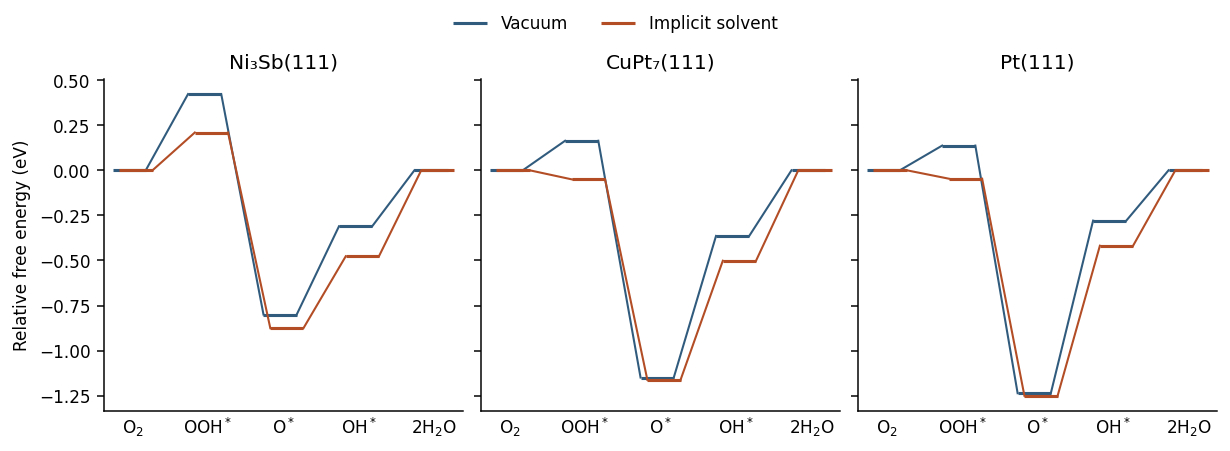

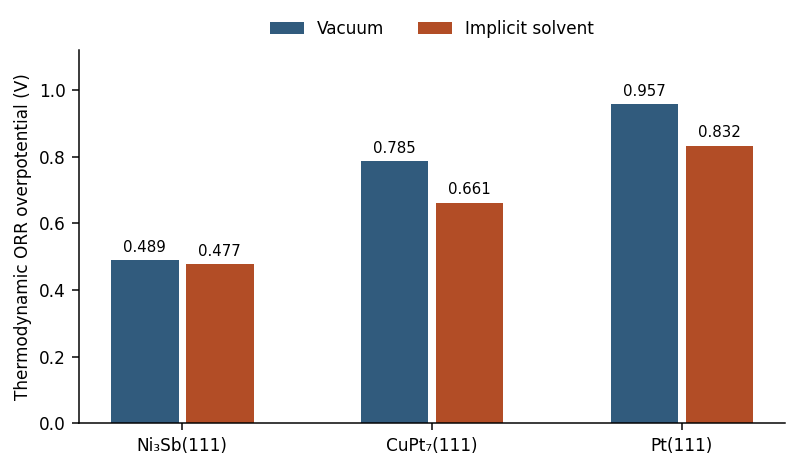

In [6]:
plt.rcParams.update({
    "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "svg.fonttype": "none",
})
COLORS = {"Vacuum": "#315B7D", "Implicit solvent": "#B24D26"}
STEP_COLUMNS = [f"DeltaG{i}_at_0V_eV" for i in range(1, 5)]


def show_and_save(fig, stem):
    """Embed a static PNG preview and export raster and vector figures."""
    paths = []
    for extension in ("png", "pdf", "svg"):
        path = RESULTS_DIR / f"{stem}.{extension}"
        fig.savefig(path, dpi=350, bbox_inches="tight")
        paths.append(path)
    with BytesIO() as preview:
        fig.savefig(preview, format="png", dpi=135, bbox_inches="tight")
        display(Image(data=preview.getvalue()))
    plt.close(fig)
    return paths


fig, axes = plt.subplots(1, 3, figsize=(9.0, 3.25), sharey=True, layout="constrained")
state_labels = (r"$\mathrm{O_2}$", r"$\mathrm{OOH^*}$", r"$\mathrm{O^*}$",
                r"$\mathrm{OH^*}$", r"$2\mathrm{H_2O}$")
x = np.arange(len(state_labels))
for ax, (surface_id, label) in zip(axes, SURFACES.items()):
    for environment in ENVIRONMENTS.values():
        values = orr.loc[(surface_id, environment), STEP_COLUMNS].to_numpy(dtype=float)
        levels = np.r_[0.0, np.cumsum(values + U_EQ_V)]
        offset = -0.045 if environment == "Vacuum" else 0.045
        px = x + offset
        color = COLORS[environment]
        ax.hlines(levels, px - 0.22, px + 0.22, color=color, linewidth=1.65, label=environment)
        for i in range(4):
            ax.plot([px[i] + 0.22, px[i + 1] - 0.22], levels[i:i+2], color=color, linewidth=1.1)
    ax.set(title=label, xticks=x, xticklabels=state_labels, xlim=(-0.38, 4.38))
    ax.tick_params(axis="x", length=0)

axes[0].set_ylabel("Relative free energy (eV)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncols=2, frameon=False)
figure_paths = show_and_save(fig, "orr_free_energy_profiles")

fig, ax = plt.subplots(figsize=(5.8, 3.35), layout="constrained")
for i, environment in enumerate(ENVIRONMENTS.values()):
    points = orr.xs(environment, level="Environment").loc[list(SURFACES), "eta_V"]
    positions = np.arange(len(SURFACES)) + (i - 0.5) * 0.30
    bars = ax.bar(positions, points, width=0.27, color=COLORS[environment], label=environment)
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=3)
ax.set(xticks=range(len(SURFACES)), xticklabels=list(SURFACES.values()),
       ylabel="Thermodynamic ORR overpotential (V)", ylim=(0, 1.12))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.12), ncols=2, frameon=False)
figure_paths += show_and_save(fig, "orr_overpotential_comparison")

## 6. Export and share the results

The results ZIP contains the molecular references, state energies, adsorption energies, ORR step energies and overpotentials, figures, and input provenance.

In [7]:
tables = {
    "01_molecular_references.csv": molecular,
    "02_surface_state_energies.csv": surface_states,
    "03_adsorption_free_energies.csv": adsorption,
    "04_orr_limiting_potentials.csv": orr,
}
for name, table in tables.items():
    table.to_csv(RESULTS_DIR / name)

provenance = {
    "data_commit": DATA_COMMIT,
    "archives": {name: {"url": f"{DATA_URL}/{name}", "sha256": digest}
                 for name, digest in INPUT_HASHES.items()},
    "temperature_K": TEMPERATURE_K,
    "molecular_reference_pressures_kPa": TARGET_PRESSURE_KPA,
    "equilibrium_potential_V_vs_RHE": U_EQ_V,
    "electronic_energy": "Final OUTCAR energy(sigma->0)",
    "solvent_energy": "Final electronic energies from archived VASPsol ionic relaxations",
    "software": {"python": sys.version.split()[0], "numpy": np.__version__,
                 "pandas": pd.__version__, "matplotlib": matplotlib.__version__},
}
provenance_path = RESULTS_DIR / "05_provenance.json"
provenance_path.write_text(json.dumps(provenance, indent=2) + "\n", encoding="utf-8")

results_zip = WORK_ROOT / "stageIII_ORR_results.zip"
export_paths = [*(RESULTS_DIR / name for name in tables), provenance_path, *figure_paths]
with ZipFile(results_zip, "w", compression=ZIP_DEFLATED) as archive:
    for path in export_paths:
        archive.write(path, arcname=path.name)
print(f"Saved {len(export_paths)} files in {results_zip.name}.")

Saved 11 files in stageIII_ORR_results.zip.
